<a href="https://colab.research.google.com/github/MilkySon/RL_carracing_competition/blob/261106-beta-ppo/ThreeStage_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DQN → Continuous BC → PPO
GPU 런타임을 선택하세요. 먼저 제공된 ZIP을 업로드합니다. 세 단계 합계 학습 예산은 30만 raw frames입니다. 이 노트북은 직접 학습 후 점수·ONNX를 생성합니다.

In [1]:
from google.colab import files
import zipfile, pathlib, os
uploaded = files.upload()
archive = next(k for k in uploaded if k.endswith(".zip"))
with zipfile.ZipFile(archive) as z: z.extractall("/content/transfer_project")
os.chdir("/content/transfer_project/rl_transfer")
!pip -q install -r requirements.txt

Saving DQN_BC_PPO_OOP.zip to DQN_BC_PPO_OOP.zip


In [2]:
!python test_contracts.py

/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
I0000 00:00:1794361055.971425     493 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794361059.075789     493 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your

## 1. DQN 교사
10,000 agent step마다 평가 결과를 출력합니다. 전체 평가에는 시간이 걸립니다.

In [3]:
!python pipeline.py --out runs/experiment01 --stage dqn --device cuda

/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
I0000 00:00:1794361075.451514     624 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794361078.517036     624 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your

## 2. 연속 actor 모방학습
시연은 raw frame 예산에 포함됩니다. BC는 10,000 gradient step마다 결과를 출력합니다.

In [4]:
!python pipeline.py --out runs/experiment01 --stage bc

/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
I0000 00:00:1794363768.309055   11692 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794363771.022837   11692 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your

## 3. PPO 미세조정
DQN 행동표에 없는 연속 행동을 탐색합니다. 좋아진다는 보장은 없으므로 세 단계 결과를 비교합니다.

In [5]:
!python pipeline.py --out runs/experiment01 --stage ppo

/usr/local/lib/python3.13/dist-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists
I0000 00:00:1794364319.828046   13952 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794364322.083148   13952 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your

{
  "dqn": {
    "mean": 86.65176262074117,
    "std": 276.4133844081624
  },
  "bc": {
    "mean": -38.35094354391235,
    "std": 52.77971155201721
  },
  "ppo": {
    "mean": -27.10570341872103,
    "std": 16.543234879646484
  },
  "paired_ppo_minus_dqn": -113.7574660394622,
  "training_frames_total": 300000
}


,seed,dqn,bc,ppo
0,2000,-52.861953,-79.797980,-36.026936
1,2001,-75.177305,-78.723404,-29.078014
2,2002,-80.988593,48.288973,-27.756654
3,2003,-81.884058,70.289855,-27.536232
4,2004,556.565657,-25.925926,7.744108
5,2005,-82.578397,-82.578397,-30.313589
6,2006,-66.145833,-84.375000,-50.520833
7,2007,-81.884058,-78.260870,-27.536232
8,2008,53.333333,63.333333,16.666667
9,2009,-81.273408,-51.310861,-28.838951


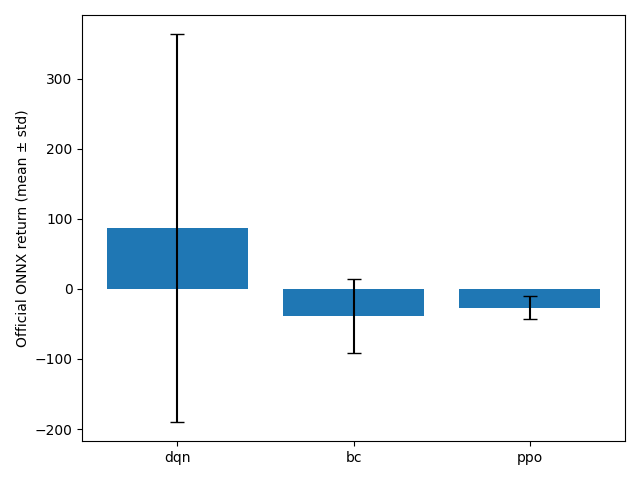

In [6]:
import json, pandas as pd
from IPython.display import display, Image
root = pathlib.Path("runs/experiment01")
print((root / "comparison.json").read_text())
display(pd.read_csv(root / "comparison.csv"))
display(Image(filename=str(root / "comparison.png")))

In [7]:
import shutil
# 시연 데이터가 커서 모델·로그·결과만 묶습니다.
result_dir = pathlib.Path("/content/transfer_results")
result_dir.mkdir(exist_ok=True)
for p in root.iterdir():
    if p.suffix in {".zip", ".onnx", ".json", ".jsonl", ".csv", ".png"}:
        shutil.copy2(p, result_dir / p.name)
shutil.make_archive("/content/transfer_results", "zip", result_dir)
files.download("/content/transfer_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>